In [1]:
# Import the libraries used for data loading, numerical operations, and visualizations.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the insurance claims CSV and preview its size and first few records.

df = pd.read_csv("insurance_claims.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (1040, 30)


,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,insured_sex,insured_education_level,...,police_report_available,auto_make,auto_year,incident_date,total_claim_amount,injury_claim,property_claim,vehicle_claim,fraud_reported,_c39
0,330,47.0,197990,2004-09-02,OH,250/500,1000,1670.57,MALE,MD,...,NO,Toyota,2008,2015-01-24,40996.0,6492.0,3396.0,31108.0,N,NaN
1,294,28.0,470873,2010-08-14,IL,250/500,1000,1269.31,Female,MD,...,NO,Audi,1995,2015-01-23,57850.0,5592.0,3214.0,49044.0,N,NaN
2,341,33.0,385683,2003-08-28,IL,100/300,2000,1174.03,FEMALE,JD,...,YES,Audi,2005,2015-01-03,49889.0,9328.0,8297.0,32264.0,N,NaN
3,318,56.0,917684,1999-06-27,IL,500/1000,2000,1195.26,FEMALE,College,...,NO,BMW,2008,2015-02-27,7562.0,758.0,311.0,6493.0,N,NaN
4,46,24.0,740436,2007-10-17,IN,250/500,2000,1204.13,Male,PhD,...,?,Audi,2006,2015-02-02,64484.0,4343.0,4609.0,55532.0,Y,NaN


In [3]:
# Inspect the dataset dimensions, column names, and data types before analysis.

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Number of rows: 1040
Number of columns: 30

Column names:
['months_as_customer', 'age', 'policy_number', 'policy_bind_date', 'policy_state', 'policy_csl', 'policy_deductable', 'policy_annual_premium', 'insured_sex', 'insured_education_level', 'insured_occupation', 'insured_hobbies', 'incident_type', 'incident_severity', 'collision_type', 'authorities_contacted', 'incident_state', 'incident_hour_of_the_day', 'number_of_vehicles_involved', 'witnesses', 'police_report_available', 'auto_make', 'auto_year', 'incident_date', 'total_claim_amount', 'injury_claim', 'property_claim', 'vehicle_claim', 'fraud_reported', '_c39']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1040 entries, 0 to 1039
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   months_as_customer           1040 non-null   int64  
 1   age                          1014 non-null   float64
 2   policy_number        

In [4]:
# Summarize numerical and categorical columns to understand the dataset's basic statistics.

display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
months_as_customer,1040.0,NaN,NaN,NaN,235.125,139.642475,0.0,112.75,231.0,352.25,479.0
age,1014.0,NaN,NaN,NaN,41.659763,13.345497,19.0,30.0,41.0,53.0,64.0
policy_number,1040.0,NaN,NaN,NaN,542072.948077,255398.962023,101780.0,327216.0,542913.0,749195.5,999794.0
policy_bind_date,1040,926,1999-11-23,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
policy_state,1040,3,IN,367,NaN,NaN,NaN,NaN,NaN,NaN,NaN
policy_csl,1040,3,500/1000,358,NaN,NaN,NaN,NaN,NaN,NaN,NaN
policy_deductable,1040.0,NaN,NaN,NaN,1149.519231,616.971834,500.0,500.0,1000.0,2000.0,2000.0
policy_annual_premium,1040.0,NaN,NaN,NaN,1241.652615,244.902543,439.97,1074.8675,1250.375,1401.635,2190.79
insured_sex,1040,4,FEMALE,511,NaN,NaN,NaN,NaN,NaN,NaN,NaN
insured_education_level,1040,6,JD,201,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Count fraud and legitimate labels and calculate their percentages to check class balance.

print("Fraud distribution:")
print(df["fraud_reported"].value_counts(dropna=False))

print("\nFraud percentage:")
print(
    (df["fraud_reported"].value_counts(normalize=True) * 100).round(2)
)

Fraud distribution:
fraud_reported
N      855
Y      175
NaN     10
Name: count, dtype: int64

Fraud percentage:
fraud_reported
N    83.01
Y    16.99
Name: proportion, dtype: float64


In [6]:
# Count missing values and calculate their percentage in each column to identify data-quality issues.

null_report = pd.DataFrame({
    "Null Count": df.isnull().sum(),
    "Null Percentage": (df.isnull().mean() * 100).round(2)
})

display(
    null_report[null_report["Null Count"] > 0]
    .sort_values("Null Count", ascending=False)
)

,Null Count,Null Percentage
_c39,1040,100.00
authorities_contacted,218,20.96
age,26,2.50
insured_occupation,22,2.12
fraud_reported,10,0.96


In [7]:
# Check for duplicate rows and preview duplicates before deciding how to clean them.

print("Total rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())

display(df[df.duplicated(keep=False)].head(10))

Total rows: 1040
Duplicate rows: 40


,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,insured_sex,insured_education_level,...,police_report_available,auto_make,auto_year,incident_date,total_claim_amount,injury_claim,property_claim,vehicle_claim,fraud_reported,_c39
6,97,37.0,555063,1998-08-28,IL,100/300,1000,1377.98,FEMALE,JD,...,NO,Audi,1998,2015-02-01,99000.0,4108.0,9790.0,85102.0,N,NaN
49,475,62.0,957060,2005-08-26,IN,500/1000,1000,1329.85,MALE,Masters,...,YES,Honda,2002,2015-02-21,78083.0,7938.0,5704.0,64441.0,N,NaN
78,349,51.0,344261,1995-04-29,OH,500/1000,500,1302.61,FEMALE,College,...,?,Honda,1996,2015-01-10,15852.0,2774.0,2899.0,10179.0,N,NaN
104,434,42.0,732463,1998-07-06,IN,100/300,2000,1014.04,FEMALE,JD,...,NO,Suburu,1996,2015-02-14,28330.0,2753.0,5383.0,20194.0,N,NaN
108,414,NaN,628472,2002-06-19,IN,250/500,500,1620.25,FEMALE,MD,...,YES,Toyota,2004,2015-01-11,73070.0,10847.0,14014.0,48209.0,Y,NaN
119,109,46.0,296828,1999-02-01,IN,100/300,2000,995.19,FEMALE,High School,...,YES,Nissan,2004,2015-01-09,48817.0,7515.0,6650.0,34652.0,N,NaN
133,413,24.0,304678,2001-02-27,IN,250/500,500,1268.63,FEMALE,JD,...,YES,Audi,1995,2015-01-13,39081.0,6651.0,2402.0,30028.0,N,NaN
142,351,45.0,859273,1995-07-08,IL,500/1000,2000,1432.73,MALE,JD,...,?,Toyota,1995,2015-02-02,33289.0,4173.0,3760.0,25356.0,N,NaN
242,188,43.0,137464,1999-09-16,IN,100/300,500,1430.62,FEMALE,JD,...,?,Toyota,2013,2015-02-23,62171.0,9981.0,3797.0,48393.0,Y,NaN
262,309,60.0,604139,2009-11-16,OH,250/500,1000,1348.13,MALE,Masters,...,YES,Saab,2009,2015-01-26,60648.0,5457.0,2125.0,53066.0,N,NaN


In [8]:
# Find placeholder or blank text values and inspect selected columns for inconsistent capitalization or spaces.

# Placeholder values such as "?" or extra spaces in text columns
text_cols = df.select_dtypes(include=["object", "string"]).columns

for col in text_cols:
    mask = df[col].astype("string").str.strip().isin(["?", ""])
    if mask.sum() > 0:
        print(f"{col}: {mask.sum()} rows with '?' or empty value")

print("\nExample of inconsistent text (extra spaces / upper-lower):")
for col in ["insured_sex", "police_report_available"]:
    if col in df.columns:
        print(col, df[col].unique().tolist())

collision_type: 194 rows with '?' or empty value
police_report_available: 357 rows with '?' or empty value

Example of inconsistent text (extra spaces / upper-lower):
insured_sex ['MALE', 'Female ', 'FEMALE', 'Male ']
police_report_available ['NO', 'YES', '?']


In [9]:
# Check claim-amount columns for missing, non-numeric, zero, or negative values.

claim_columns = ["total_claim_amount", "injury_claim", "property_claim", "vehicle_claim"]

for col in claim_columns:
    if col in df.columns:
        amount_numeric = pd.to_numeric(df[col], errors="coerce")
        invalid_amount = amount_numeric.isna() | (amount_numeric <= 0)
        print(f"{col}: {invalid_amount.sum()} invalid or missing rows")

display(df.loc[
    pd.to_numeric(df["total_claim_amount"], errors="coerce").le(0),
    ["total_claim_amount", "incident_type", "fraud_reported"]
].head(10))

total_claim_amount: 0 invalid or missing rows
injury_claim: 0 invalid or missing rows
property_claim: 0 invalid or missing rows
vehicle_claim: 0 invalid or missing rows


,total_claim_amount,incident_type,fraud_reported


In [10]:
# Flag values outside the chosen plausible ranges for age, customer tenure, and incident hour.

invalid_age = df["age"].lt(16) | df["age"].gt(100)
invalid_months = df["months_as_customer"].lt(0)
invalid_hour = df["incident_hour_of_the_day"].lt(0) | df["incident_hour_of_the_day"].gt(23)

print("Invalid age rows:", invalid_age.sum())
print("Invalid months_as_customer rows:", invalid_months.sum())
print("Invalid incident hour rows:", invalid_hour.sum())

display(df.loc[invalid_age, ["age", "fraud_reported"]].head(10))

Invalid age rows: 0
Invalid months_as_customer rows: 0
Invalid incident hour rows: 0


,age,fraud_reported


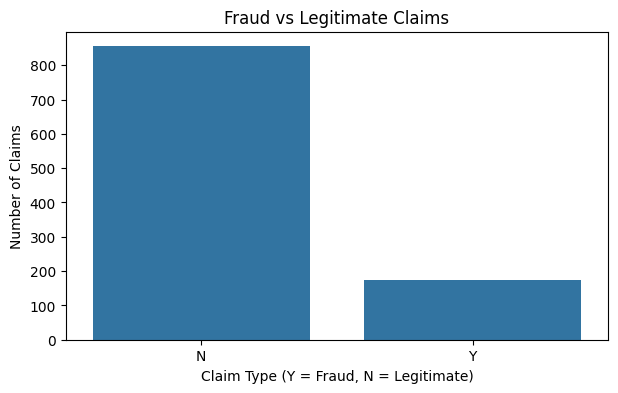

In [11]:
# Visualize the number of fraud and legitimate claims to understand the target distribution.

plt.figure(figsize=(7, 4))

sns.countplot(data=df, x="fraud_reported")

plt.title("Fraud vs Legitimate Claims")
plt.xlabel("Claim Type (Y = Fraud, N = Legitimate)")
plt.ylabel("Number of Claims")
plt.show()

In [12]:
# Create a working copy of the original data and remove exact duplicate rows from that copy.

clean_df = df.copy()

print("Rows before cleaning:", len(clean_df))

clean_df = clean_df.drop_duplicates().copy()

print("Rows after removing duplicates:", len(clean_df))

Rows before cleaning: 1040
Rows after removing duplicates: 1000


In [13]:
# Standardize text formatting and mark placeholder or blank text values as unknown or missing.

text_columns = clean_df.select_dtypes(include=["object", "string"]).columns.tolist()

for col in text_columns:
    clean_df[col] = (
        clean_df[col]
        .astype("string")
        .str.strip()
        .str.lower()
    )

# "?" means unknown, and empty text means missing
clean_df[text_columns] = clean_df[text_columns].replace("?", "unknown")
clean_df[text_columns] = clean_df[text_columns].replace(r"^\s*$", pd.NA, regex=True)

print("Text columns cleaned.")

Text columns cleaned.


In [14]:
# Convert fraud labels to numeric classes, then remove rows whose target label is missing.

# Target: Y -> 1 (fraud), N -> 0 (legitimate)
clean_df["fraud_reported"] = clean_df["fraud_reported"].map({"y": 1, "n": 0})

print("Missing target rows:", clean_df["fraud_reported"].isna().sum())

clean_df = clean_df.dropna(subset=["fraud_reported"]).copy()
clean_df["fraud_reported"] = clean_df["fraud_reported"].astype(int)

print("Fraud labels:")
print(clean_df["fraud_reported"].value_counts())

Missing target rows: 10
Fraud labels:
fraud_reported
0    823
1    167
Name: count, dtype: int64


In [15]:
# Convert claim amounts to numeric values and mark non-positive amounts as missing.

for col in ["total_claim_amount", "injury_claim", "property_claim", "vehicle_claim"]:
    if col in clean_df.columns:
        clean_df[col] = pd.to_numeric(clean_df[col], errors="coerce")

        # Claim amount should be positive
        clean_df.loc[clean_df[col] <= 0, col] = np.nan

print("Claim amount data types:")
print(clean_df[["total_claim_amount", "injury_claim", "property_claim", "vehicle_claim"]].dtypes)
print("Invalid/missing total claim amounts:", clean_df["total_claim_amount"].isna().sum())

Claim amount data types:
total_claim_amount    float64
injury_claim          float64
property_claim        float64
vehicle_claim         float64
dtype: object
Invalid/missing total claim amounts: 0


In [16]:
# Mark age, customer-tenure, and incident-hour values outside the selected ranges as missing.

clean_df.loc[
    ~clean_df["age"].between(16, 100), "age"
] = np.nan

clean_df.loc[
    clean_df["months_as_customer"] < 0, "months_as_customer"
] = np.nan

clean_df.loc[
    ~clean_df["incident_hour_of_the_day"].between(0, 23), "incident_hour_of_the_day"
] = np.nan

print("Invalid age, months and hour values marked as missing.")

Invalid age, months and hour values marked as missing.


In [17]:
# Remove duplicates that may have become identical after text standardization.

# Text cleaning can create new duplicate rows, so remove duplicates again
before = len(clean_df)
clean_df = clean_df.drop_duplicates().copy()

print("Extra duplicates removed:", before - len(clean_df))

Extra duplicates removed: 0


In [18]:
# Convert date columns to datetime and derive calendar and policy-to-incident features.

clean_df["incident_date"] = pd.to_datetime(
    clean_df["incident_date"],
    errors="coerce"
)

clean_df["policy_bind_date"] = pd.to_datetime(
    clean_df["policy_bind_date"],
    errors="coerce"
)

clean_df["incident_month"] = clean_df["incident_date"].dt.month
clean_df["incident_day"] = clean_df["incident_date"].dt.day
clean_df["incident_dayofweek"] = clean_df["incident_date"].dt.dayofweek
clean_df["days_policy_to_incident"] = (
    clean_df["incident_date"] - clean_df["policy_bind_date"]
).dt.days

display(
    clean_df[
        ["incident_date", "incident_month", "incident_day", "incident_dayofweek", "days_policy_to_incident"]
    ].head()
)

,incident_date,incident_month,incident_day,incident_dayofweek,days_policy_to_incident
0,2015-01-24,1,24,5,3796
1,2015-01-23,1,23,4,1623
2,2015-01-03,1,3,5,4146
3,2015-02-27,2,27,4,5724
4,2015-02-02,2,2,0,2665


In [19]:
# Review the cleaned dataset's shape, remaining missing values, duplicate count, and sample rows.

print("Cleaned dataset shape:", clean_df.shape)

print("\nRemaining null values:")
display(
    clean_df.isnull().sum()
    .loc[lambda x: x > 0]
    .sort_values(ascending=False)
)

print("\nRemaining duplicates:", clean_df.duplicated().sum())

display(clean_df.head())

Cleaned dataset shape: (990, 34)

Remaining null values:


_c39                     990
authorities_contacted    202
age                       25
insured_occupation        20
dtype: int64


Remaining duplicates: 0


,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,insured_sex,insured_education_level,...,total_claim_amount,injury_claim,property_claim,vehicle_claim,fraud_reported,_c39,incident_month,incident_day,incident_dayofweek,days_policy_to_incident
0,330.0,47.0,197990,2004-09-02,oh,250/500,1000,1670.57,male,md,...,40996.0,6492.0,3396.0,31108.0,0,NaN,1,24,5,3796
1,294.0,28.0,470873,2010-08-14,il,250/500,1000,1269.31,female,md,...,57850.0,5592.0,3214.0,49044.0,0,NaN,1,23,4,1623
2,341.0,33.0,385683,2003-08-28,il,100/300,2000,1174.03,female,jd,...,49889.0,9328.0,8297.0,32264.0,0,NaN,1,3,5,4146
3,318.0,56.0,917684,1999-06-27,il,500/1000,2000,1195.26,female,college,...,7562.0,758.0,311.0,6493.0,0,NaN,2,27,4,5724
4,46.0,24.0,740436,2007-10-17,in,250/500,2000,1204.13,male,phd,...,64484.0,4343.0,4609.0,55532.0,1,NaN,2,2,0,2665


In [20]:
# Calculate the percentage of legitimate and fraud claims in the cleaned dataset.

fraud_percentage = (
    clean_df["fraud_reported"].value_counts(normalize=True) * 100
)

display(fraud_percentage.rename({
    0: "Legitimate (%)",
    1: "Fraud (%)"
}).to_frame("Percentage"))

,Percentage
fraud_reported,
Legitimate (%),83.131313
Fraud (%),16.868687


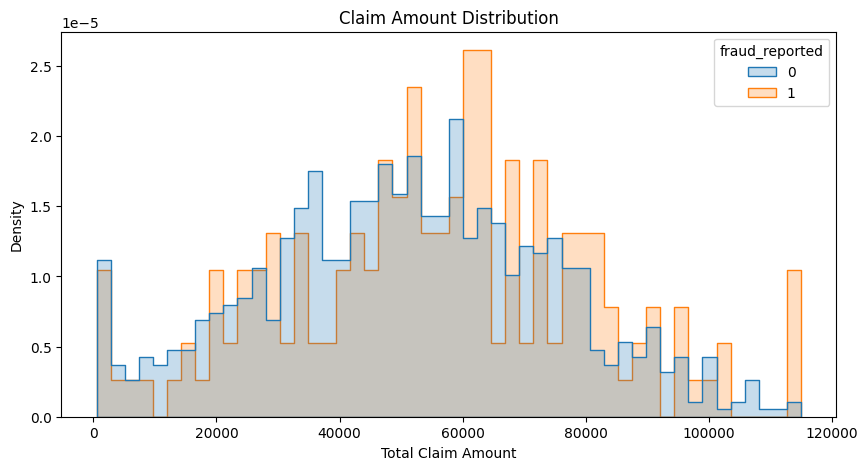

In [21]:
# Compare the distribution of total claim amounts for fraud and legitimate claims.

plt.figure(figsize=(10, 5))

sns.histplot(
    data=clean_df,
    x="total_claim_amount",
    hue="fraud_reported",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Claim Amount Distribution")
plt.xlabel("Total Claim Amount")
plt.ylabel("Density")
plt.show()

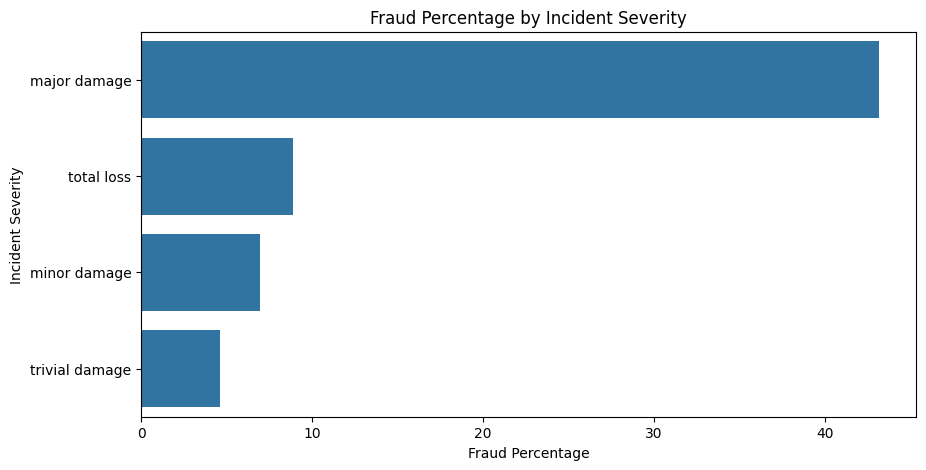

In [22]:
# Calculate and visualize the fraud percentage for each incident-severity category.

fraud_by_severity = (
    clean_df.groupby("incident_severity")["fraud_reported"]
    .mean()
    .sort_values(ascending=False) * 100
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=fraud_by_severity.values,
    y=fraud_by_severity.index
)

plt.title("Fraud Percentage by Incident Severity")
plt.xlabel("Fraud Percentage")
plt.ylabel("Incident Severity")
plt.show()

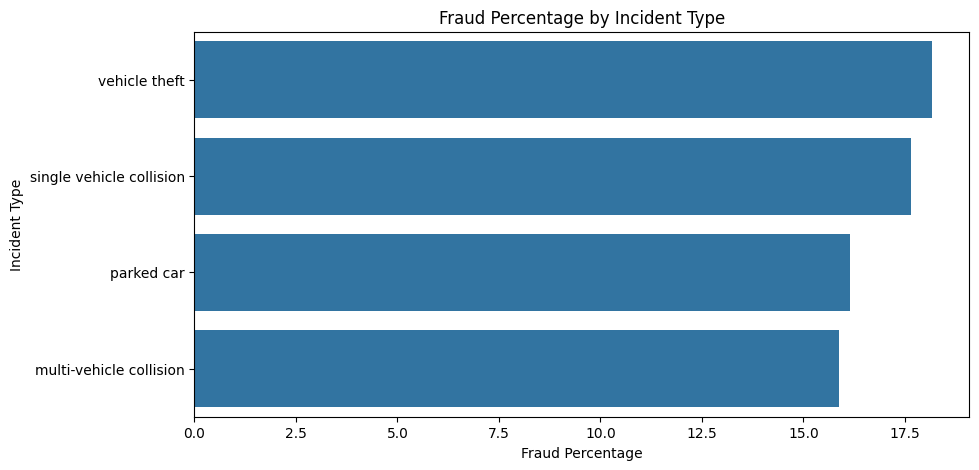

In [23]:
# Calculate and visualize the fraud percentage for each incident-type category.

fraud_by_type = (
    clean_df.groupby("incident_type")["fraud_reported"]
    .mean()
    .sort_values(ascending=False) * 100
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=fraud_by_type.values,
    y=fraud_by_type.index
)

plt.title("Fraud Percentage by Incident Type")
plt.xlabel("Fraud Percentage")
plt.ylabel("Incident Type")
plt.show()

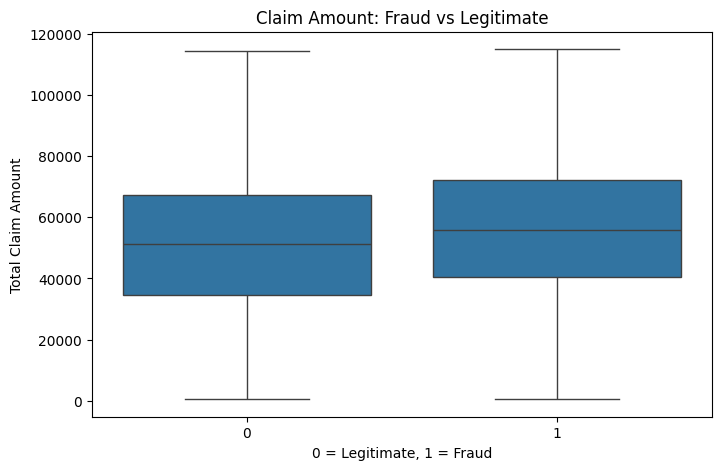

In [24]:
# Compare claim-amount distributions for legitimate and fraud labels using a box plot.

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=clean_df,
    x="fraud_reported",
    y="total_claim_amount"
)

plt.title("Claim Amount: Fraud vs Legitimate")
plt.xlabel("0 = Legitimate, 1 = Fraud")
plt.ylabel("Total Claim Amount")
plt.show()

In [25]:
# Choose available input features, separate the target label, and prepare X and y for modeling.

from sklearn.model_selection import train_test_split

features = [
    "incident_severity",
    "incident_type",
    "collision_type",
    "authorities_contacted",
    "insured_sex",
    "insured_education_level",
    "insured_occupation",
    "insured_hobbies",
    "police_report_available",
    "age",
    "months_as_customer",
    "policy_annual_premium",
    "policy_deductable",
    "total_claim_amount",
    "injury_claim",
    "property_claim",
    "vehicle_claim",
    "witnesses",
    "number_of_vehicles_involved",
    "incident_hour_of_the_day",
    "incident_month",
    "incident_day",
    "incident_dayofweek",
    "days_policy_to_incident"
]

# Keep only the columns that exist in your dataset
features = [col for col in features if col in clean_df.columns]

model_df = clean_df.dropna(subset=["fraud_reported"]).copy()

X = model_df[features]
y = model_df["fraud_reported"].astype(int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (990, 24)
Target shape: (990,)

Target distribution:
fraud_reported
0    823
1    167
Name: count, dtype: int64


In [26]:
# Split the data into training and testing sets while preserving the target-class proportions.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training rows: 792
Testing rows: 198

Training class distribution:
fraud_reported
0    658
1    134
Name: count, dtype: int64

Testing class distribution:
fraud_reported
0    165
1     33
Name: count, dtype: int64


In [27]:
# Review the training-set class balance; retain all training rows and use class weights to address imbalance.

print("Training class distribution:")
print(y_train.value_counts())

fraud_ratio = y_train.mean()
print("\nFraud share in training data:", round(fraud_ratio * 100, 2), "%")

# The dataset is small, so we do NOT delete legitimate rows.
# Instead the models use class_weight="balanced" to give fraud claims more importance.
print("Using ALL", len(X_train), "training rows with class weights.")

Training class distribution:
fraud_reported
0    658
1    134
Name: count, dtype: int64

Fraud share in training data: 16.92 %
Using ALL 792 training rows with class weights.


In [28]:
# Inspect missing values and data types in the training features before preprocessing.

print("Missing values in training data:")

display(
    X_train.isna().sum()
    .sort_values(ascending=False)
    .head(20)
)

print("\nData types:")
print(X_train.dtypes)

Missing values in training data:


authorities_contacted          167
age                             20
insured_occupation              18
incident_type                    0
collision_type                   0
insured_sex                      0
insured_education_level          0
incident_severity                0
insured_hobbies                  0
police_report_available          0
months_as_customer               0
policy_annual_premium            0
policy_deductable                0
total_claim_amount               0
injury_claim                     0
property_claim                   0
vehicle_claim                    0
witnesses                        0
number_of_vehicles_involved      0
incident_hour_of_the_day         0
dtype: int64


Data types:
incident_severity               string
incident_type                   string
collision_type                  string
authorities_contacted           string
insured_sex                     string
insured_education_level         string
insured_occupation              string
insured_hobbies                 string
police_report_available         string
age                            float64
months_as_customer             float64
policy_annual_premium          float64
policy_deductable                int64
total_claim_amount             float64
injury_claim                   float64
property_claim                 float64
vehicle_claim                  float64
witnesses                        int64
number_of_vehicles_involved      int64
incident_hour_of_the_day       float64
incident_month                   int32
incident_day                     int32
incident_dayofweek               int32
days_policy_to_incident          int64
dtype: object


In [29]:
# Standardize pandas missing-value markers so preprocessing handles them consistently.

import pandas as pd
import numpy as np

X_train = X_train.replace(
    {pd.NA: np.nan}
)

X_test = X_test.replace(
    {pd.NA: np.nan}
)

print("Missing values standardized.")

Missing values standardized.


In [30]:
# Separate categorical and numerical features and correct their data types for preprocessing.

categorical_features = [
    col for col in features
    if clean_df[col].dtype == "object" or str(clean_df[col].dtype) == "string"
]

numeric_features = [col for col in features if col not in categorical_features]

for col in numeric_features:
    X_train[col] = pd.to_numeric(X_train[col], errors="coerce")
    X_test[col] = pd.to_numeric(X_test[col], errors="coerce")

for col in categorical_features:
    X_train[col] = X_train[col].astype("object")
    X_test[col] = X_test[col].astype("object")

    X_train[col] = X_train[col].where(X_train[col].notna(), np.nan)
    X_test[col] = X_test[col].where(X_test[col].notna(), np.nan)

print("Categorical features:", categorical_features)
print("Numeric features:", numeric_features)
print("\nColumn data types corrected.")

Categorical features: ['incident_severity', 'incident_type', 'collision_type', 'authorities_contacted', 'insured_sex', 'insured_education_level', 'insured_occupation', 'insured_hobbies', 'police_report_available']
Numeric features: ['age', 'months_as_customer', 'policy_annual_premium', 'policy_deductable', 'total_claim_amount', 'injury_claim', 'property_claim', 'vehicle_claim', 'witnesses', 'number_of_vehicles_involved', 'incident_hour_of_the_day', 'incident_month', 'incident_day', 'incident_dayofweek', 'days_policy_to_incident']

Column data types corrected.


In [31]:
# Build preprocessing pipelines to impute missing values, scale numeric features, and encode categories.

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [32]:
# Define four classification models, combine three with soft voting, and train each full pipeline.

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier

log_reg = LogisticRegression(max_iter=3000, C=0.3, class_weight="balanced")

rand_forest = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=3,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

grad_boost = GradientBoostingClassifier(
    n_estimators=150,
    max_depth=2,
    learning_rate=0.05,
    subsample=0.8,
    random_state=42
)

# Voting model: averages the fraud probability of the three models
voting = VotingClassifier(
    estimators=[("lr", log_reg), ("rf", rand_forest), ("gb", grad_boost)],
    voting="soft"
)

all_models = {
    "Logistic Regression": Pipeline([("preprocessing", preprocessor), ("classifier", log_reg)]),
    "Random Forest": Pipeline([("preprocessing", preprocessor), ("classifier", rand_forest)]),
    "Gradient Boosting": Pipeline([("preprocessing", preprocessor), ("classifier", grad_boost)]),
    "Voting (All 3)": Pipeline([("preprocessing", preprocessor), ("classifier", voting)])
}

print("Training models...")

for name, m in all_models.items():
    m.fit(X_train, y_train)
    print(name, "trained")

print("\nModel training completed!")

Training models...
Logistic Regression trained


Random Forest trained


Gradient Boosting trained


Voting (All 3) trained

Model training completed!


In [33]:
# Use stratified cross-validation on training data to choose a probability threshold that meets the recall target.

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Find the best fraud threshold using ONLY the training data (cross-validation).
# Rule: catch at least 60% of fraud claims, and keep accuracy as high as possible.
MIN_RECALL = 0.60

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

tuning_rows = []
thresholds = {}

for name, m in all_models.items():
    oof_prob = cross_val_predict(m, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

    best_t, best_acc = 0.5, 0
    for t in np.arange(0.05, 0.90, 0.01):
        pred = (oof_prob >= t).astype(int)
        if recall_score(y_train, pred) >= MIN_RECALL:
            acc = accuracy_score(y_train, pred)
            if acc > best_acc:
                best_t, best_acc = t, acc

    thresholds[name] = best_t
    tuning_rows.append({
        "Model": name,
        "CV ROC-AUC": roc_auc_score(y_train, oof_prob),
        "Best Threshold": best_t,
        "CV Accuracy": best_acc
    })

tuning_df = pd.DataFrame(tuning_rows).set_index("Model").round(4)
display(tuning_df)

,CV ROC-AUC,Best Threshold,CV Accuracy
Model,,,
Logistic Regression,0.7522,0.57,0.7778
Random Forest,0.7324,0.34,0.7942
Gradient Boosting,0.7481,0.21,0.7740
Voting (All 3),0.7507,0.36,0.7778


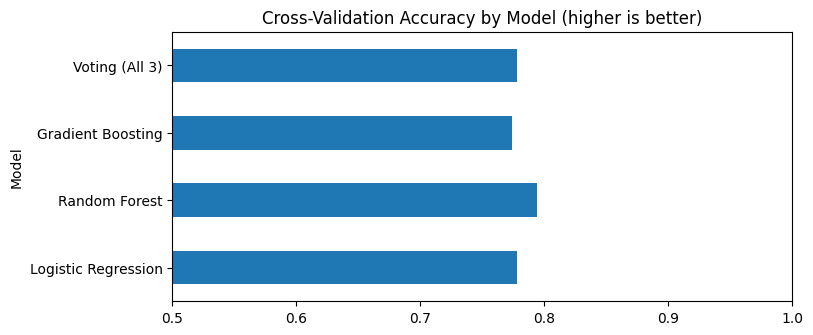

In [34]:
# Visualize cross-validation accuracy for the candidate models to compare their training-only selection scores.

tuning_df["CV Accuracy"].plot(kind="barh", figsize=(8, 3.5))

plt.title("Cross-Validation Accuracy by Model (higher is better)")
plt.xlim(0.5, 1)
plt.show()

In [35]:
# Select the model with the highest cross-validation accuracy and retrieve its tuned fraud threshold.

# Best model = highest cross-validation accuracy (chosen on training data only)
best_name = tuning_df["CV Accuracy"].idxmax()
model = all_models[best_name]
THRESHOLD = thresholds[best_name]

print("Best model:", best_name)
print("Fraud threshold:", round(THRESHOLD, 2))

Best model: Random Forest
Fraud threshold: 0.34


In [36]:
# Predict fraud probabilities on the held-out test set and convert them to labels using the selected threshold.

y_prob = model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= THRESHOLD).astype(int)

print("Predictions completed!")

print("First 20 actual values:")
print(y_test.head(20).to_list())

print("\nFirst 20 predicted values:")
print(y_pred[:20])

Predictions completed!
First 20 actual values:
[0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1]

First 20 predicted values:
[0 0 0 1 0 0 1 0 0 1 0 1 0 1 1 1 1 1 1 1]


In [37]:
# Compare the standard 0.5 threshold with the tuned threshold using test-set classification metrics.

# Default threshold (0.5) vs tuned threshold
default_pred = (y_prob >= 0.5).astype(int)

compare = pd.DataFrame({
    "Default threshold 0.5": {
        "Accuracy": accuracy_score(y_test, default_pred),
        "Precision": precision_score(y_test, default_pred, zero_division=0),
        "Recall": recall_score(y_test, default_pred, zero_division=0),
        "F1 Score": f1_score(y_test, default_pred, zero_division=0)
    },
    f"Tuned threshold {THRESHOLD:.2f}": {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    }
}).T.round(4)

display(compare)

,Accuracy,Precision,Recall,F1 Score
Default threshold 0.5,0.8333,0.5000,0.3030,0.3774
Tuned threshold 0.34,0.8030,0.4516,0.8485,0.5895


In [38]:
# Calculate test-set Accuracy, Precision, Recall, F1, ROC-AUC, and a detailed classification report.

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nAccuracy if we always say 'Legitimate':", round(1 - y_test.mean(), 4), "(but it catches 0% of fraud)")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

Accuracy: 0.803
Precision: 0.4516
Recall: 0.8485
F1 Score: 0.5895
ROC-AUC: 0.8443

Accuracy if we always say 'Legitimate': 0.8333 (but it catches 0% of fraud)

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.96      0.79      0.87       165
       Fraud       0.45      0.85      0.59        33

    accuracy                           0.80       198
   macro avg       0.71      0.82      0.73       198
weighted avg       0.88      0.80      0.82       198



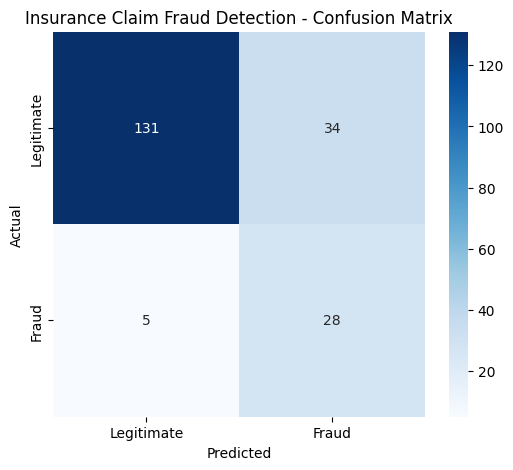

Caught 28 of 33 fraud claims | 34 honest claims flagged | 5 fraud claims missed


In [39]:
# Plot the confusion matrix to show correct and incorrect predictions for each class.

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Insurance Claim Fraud Detection - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Caught {tp} of {tp + fn} fraud claims | {fp} honest claims flagged | {fn} fraud claims missed")

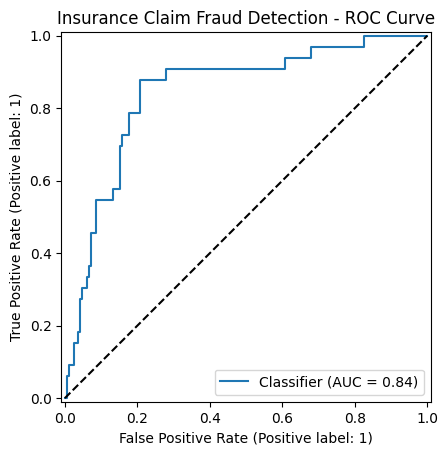

In [40]:
# Plot the ROC curve to assess how well the model separates fraud from legitimate claims across thresholds.

from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.plot([0, 1], [0, 1], "k--")
plt.title("Insurance Claim Fraud Detection - ROC Curve")
plt.show()

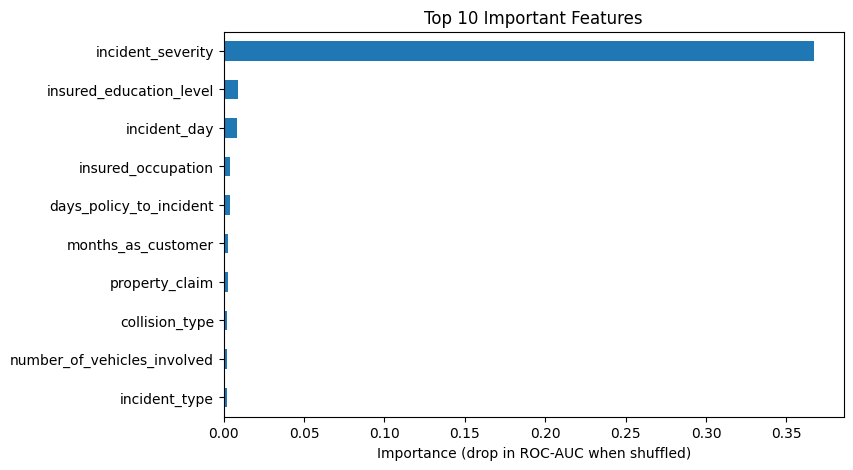

In [41]:
# Estimate feature importance by measuring the ROC-AUC change when each test feature is shuffled.

from sklearn.inspection import permutation_importance

result = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42
)

importance = pd.Series(result.importances_mean, index=X_test.columns).sort_values().tail(10)

plt.figure(figsize=(8, 5))
importance.plot(kind="barh")
plt.title("Top 10 Important Features")
plt.xlabel("Importance (drop in ROC-AUC when shuffled)")
plt.show()

In [42]:
# Save the trained model and its selected threshold so they can be reused without retraining.

import joblib

joblib.dump({"model": model, "threshold": THRESHOLD}, "insurance_claim_fraud_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [43]:
# Create an example new insurance claim with the feature fields expected by the trained model.

new_claim = pd.DataFrame([{
    "incident_severity": "major damage",
    "incident_type": "single vehicle collision",
    "collision_type": "front collision",
    "authorities_contacted": "police",
    "insured_sex": "male",
    "insured_education_level": "jd",
    "insured_occupation": "sales",
    "insured_hobbies": "chess",
    "police_report_available": "no",
    "age": 35,
    "months_as_customer": 120,
    "policy_annual_premium": 1250.0,
    "policy_deductable": 1000,
    "total_claim_amount": 70000,
    "injury_claim": 7000,
    "property_claim": 8000,
    "vehicle_claim": 55000,
    "witnesses": 0,
    "number_of_vehicles_involved": 1,
    "incident_hour_of_the_day": 22,
    "incident_month": 1,
    "incident_day": 14,
    "incident_dayofweek": 2,
    "days_policy_to_incident": 2000
}])

# Keep only the columns used by the model
new_claim = new_claim[[col for col in features if col in new_claim.columns]]

display(new_claim)

,incident_severity,incident_type,collision_type,authorities_contacted,insured_sex,insured_education_level,insured_occupation,insured_hobbies,police_report_available,age,...,injury_claim,property_claim,vehicle_claim,witnesses,number_of_vehicles_involved,incident_hour_of_the_day,incident_month,incident_day,incident_dayofweek,days_policy_to_incident
0,major damage,single vehicle collision,front collision,police,male,jd,sales,chess,no,35,...,7000,8000,55000,0,1,22,1,14,2,2000


In [44]:
# Calculate the example claim's fraud probability and compare it with the selected threshold for a prediction.

fraud_probability = model.predict_proba(new_claim)[0][1]

print("Fraud probability:", round(fraud_probability * 100, 2), "%")
print("Fraud threshold:", round(THRESHOLD * 100, 2), "%")

if fraud_probability >= THRESHOLD:
    print("Result: FRAUDULENT CLAIM")
else:
    print("Result: LEGITIMATE CLAIM")

Fraud probability: 62.62 %
Fraud threshold: 34.0 %
Result: FRAUDULENT CLAIM
